# Preprocessing walkthrough

How a PKU-Market-PCB photo becomes training data for the two diffusion models, one step at a time, with a picture at each step.

| Step | What happens |
|---|---|
| 1 | Read a photo and its YOLO labels |
| 2 | Split by board: train on 01, 04–09, keep 10–12 for testing |
| 3 | Shrink to 0.5× so pads and defects match the checkpoints' scale |
| 4 | Cut 64×64 patches centred on each defect; oversized ones are rescaled, not dropped → **64 defect model** |
| 5 | Erase defects with a per-board median template, then cut 256×256 crops on an even grid → **256 defect-free model** |
| 6 | Load the results with the repo's own `load_data`, to prove the format is right |
| 7 | Optional: run steps 3–5 over all training images |
| 8 | Verify every defect-free crop against the clean board and repair the failures |

Steps 1–6 only write a few demo files to `results/preprocess_demo/`. Step 7 writes the full dataset and is off by default (`BUILD = False`).

Run in the `crg-defect` kernel.

In [1]:
%matplotlib inline
import json
import math
import random
import shutil
import sys
from pathlib import Path

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# 找到 Graduate_Design/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "third_party" / "CRG-DefectDiffuser").is_dir())
REPO = ROOT / "third_party" / "CRG-DefectDiffuser"
PKU = ROOT / "data" / "PKU-Market-PCB-corrected"
sys.path.insert(0, str(REPO))

PKU_CLASSES = (PKU / "classes.txt").read_text().split()            # missing_hole, mouse_bite, ...
PCB_JSON = json.load(open(REPO / "data" / "pcb.json"))             # missinghole -> 0, ...
NAME = {i: n.replace("_", "") for i, n in enumerate(PKU_CLASSES)}  # PKU id -> pcb.json 名称（去掉下划线）
assert all(PCB_JSON[NAME[i]] == i for i in NAME), "PKU 与 pcb.json 的类别 id 不一致"

# 划分文件里是带 .jpg 的文件名，这里统一去掉扩展名
TRAIN = [Path(s).stem for s in (PKU / "ImageSets" / "train_board.txt").read_text().split()]
VAL = [Path(s).stem for s in (PKU / "ImageSets" / "val_board.txt").read_text().split()]
COLORS = plt.cm.tab10.colors
print("classes:", NAME)
print(f"train images {len(TRAIN)} · val images {len(VAL)}")

classes: {0: 'missinghole', 1: 'mousebite', 2: 'opencircuit', 3: 'short', 4: 'spur', 5: 'spuriouscopper'}
train images 541 · val images 152


## Settings

In [2]:
SCALE = 0.5            # 先缩放整张照片；0.5 与作者 checkpoint 的像素尺度一致
PATCH = 64             # 缺陷模型输入尺寸
FREE = 256             # 背景模型输入尺寸
MAX_OFFSET = 8         # 缺陷块中心的随机偏移（像素，缩放后），避免缺陷总在正中
RESCALE_FIT = 0.75     # 超大框：放大窗口，使框占窗口边长的 75%，再缩回 64
FREE_MARGIN = 8        # 去缺陷时标注框外扩的像素（缩放后）
EDGE_MARGIN = 32       # 无缺陷裁剪离图像边缘的距离：照片四周有 0–27 px 的灰色背景（0.5× 下）
EXAMPLE = "01_short_17"
SEED = 0

DEMO_DIR = ROOT / "results" / "preprocess_demo"     # 步骤 1–6 的少量示例输出
OUT_DIR = ROOT / "data" / "pcb_processed"           # 步骤 7 的完整数据集

## Step 1 · Read a photo and its labels

Each line of `labels/<name>.txt` is `class cx cy w h`, normalised to 0–1. Multiplying by the image width and height gives a pixel box.

image size: (3034, 1586)
raw label lines:
3 0.187376 0.588903 0.018787 0.040353
3 0.191167 0.680643 0.014502 0.037201
3 0.383652 0.868537 0.017798 0.039723
3 0.209459 0.572194 0.014173 0.027112

  short          x   540.0–  597.0  y   902.0–  966.0  size  57.0 ×  64.0 px
  short          x   558.0–  602.0  y  1050.0– 1109.0  size  44.0 ×  59.0 px
  short          x  1137.0– 1191.0  y  1346.0– 1409.0  size  54.0 ×  63.0 px
  short          x   614.0–  657.0  y   886.0–  929.0  size  43.0 ×  43.0 px


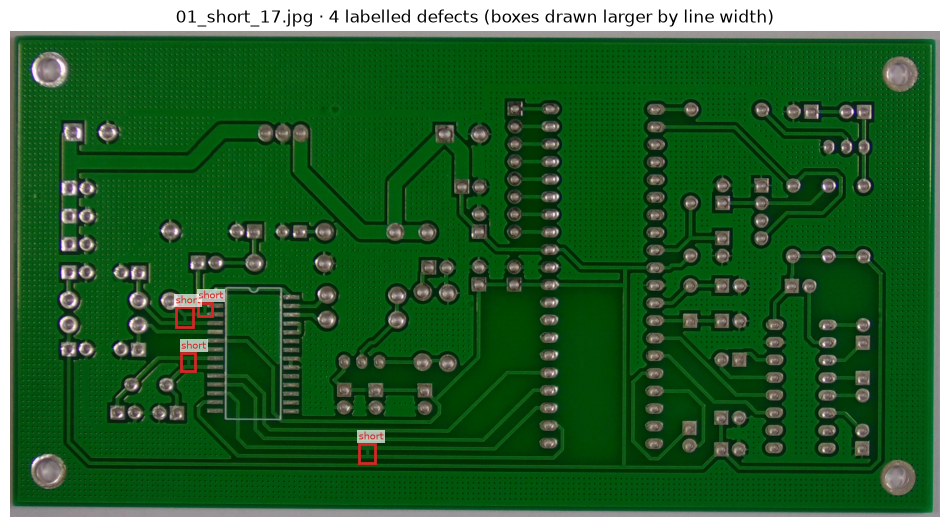

In [3]:
def load(stem):
    """返回 (PIL 图像, [(类别 id, x0, y0, x1, y1) 像素框])"""
    img = Image.open(PKU / "images" / f"{stem}.jpg").convert("RGB")
    W, H = img.size
    boxes = []
    for line in (PKU / "labels" / f"{stem}.txt").read_text().splitlines():
        c, cx, cy, w, h = line.split()
        c, cx, cy, w, h = int(c), float(cx) * W, float(cy) * H, float(w) * W, float(h) * H
        boxes.append((c, cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2))
    return img, boxes


def draw_boxes(ax, boxes, color=None, lw=1.5, label=True):
    for c, x0, y0, x1, y1 in boxes:
        col = color or COLORS[c]
        ax.add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=col, lw=lw))
        if label:
            ax.text(x0, y0 - 6, NAME[c], color=col, fontsize=7, va="bottom",
                    bbox=dict(fc="white", ec="none", alpha=0.7, pad=1))


img, boxes = load(EXAMPLE)
print("image size:", img.size)
print("raw label lines:")
print((PKU / "labels" / f"{EXAMPLE}.txt").read_text())
for c, x0, y0, x1, y1 in boxes:
    print(f"  {NAME[c]:14s} x {x0:7.1f}–{x1:7.1f}  y {y0:7.1f}–{y1:7.1f}  size {x1-x0:5.1f} × {y1-y0:5.1f} px")

fig, ax = plt.subplots(figsize=(12, 6.5))
ax.imshow(img); draw_boxes(ax, boxes, lw=2); ax.set_axis_off()
ax.set_title(f"{EXAMPLE}.jpg · {len(boxes)} labelled defects (boxes drawn larger by line width)")
plt.show()

## Step 2 · Split by board

All photos of one board are nearly identical, so the split is by **board**, not by photo. Boards 10–12 never enter training; the evaluation later uses them.

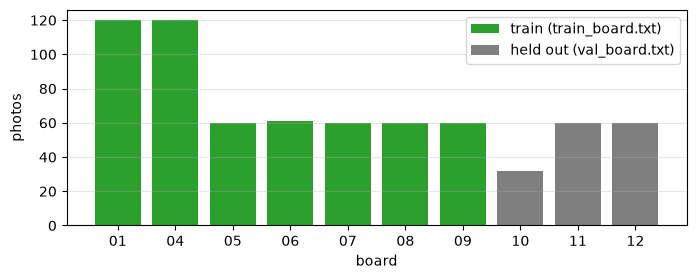

In [4]:
def board(stem):
    return stem[:2]

counts = {}
for s in TRAIN + VAL:
    counts.setdefault(board(s), [0, 0])[0 if s in TRAIN else 1] += 1
bs = sorted(counts)
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.bar(bs, [counts[b][0] for b in bs], color="tab:green", label="train (train_board.txt)")
ax.bar(bs, [counts[b][1] for b in bs], color="tab:gray", label="held out (val_board.txt)")
ax.set_xlabel("board"), ax.set_ylabel("photos"), ax.legend(), ax.grid(axis="y", alpha=0.3)
plt.show()

## Step 3 · Shrink to 0.5×

The defect model sees a 64×64 window. At full resolution many defects are bigger than that, and the authors' checkpoints were trained at about 0.5× (their pads are ~20 px, PKU pads are ~45 px at full size). Shrinking first fixes both.

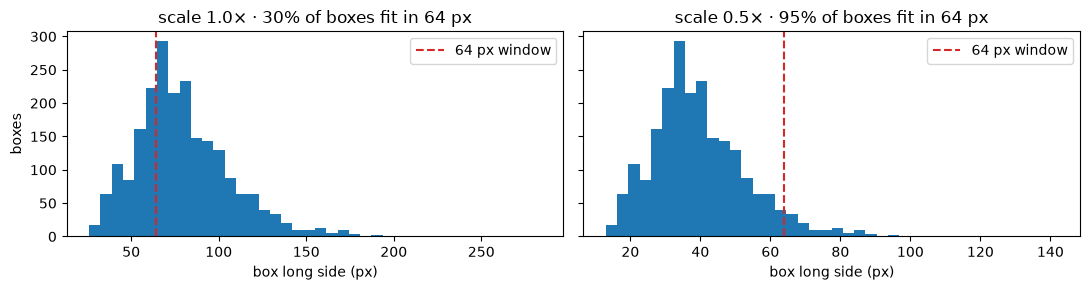

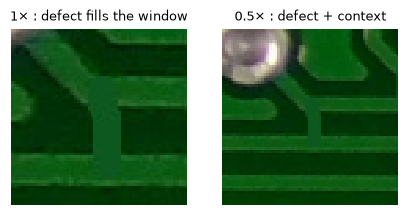

In [5]:
sizes = []                                      # 训练板上每个框的长边（原始像素）
for s in TRAIN:
    with Image.open(PKU / "images" / f"{s}.jpg") as im:
        W, H = im.size
    for line in (PKU / "labels" / f"{s}.txt").read_text().splitlines():
        _, _, _, w, h = map(float, line.split())
        sizes.append(max(w * W, h * H))
sizes = np.array(sizes)

fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for ax, sc in zip(axes, [1.0, SCALE]):
    v = sizes * sc
    ax.hist(v, bins=40, color="tab:blue")
    ax.axvline(PATCH, color="tab:red", ls="--", label=f"{PATCH} px window")
    ax.set_title(f"scale {sc}× · {np.mean(v <= PATCH):.0%} of boxes fit in {PATCH} px")
    ax.set_xlabel("box long side (px)"), ax.legend()
axes[0].set_ylabel("boxes")
plt.tight_layout(); plt.show()

# 同一个缺陷，在 1× 和 0.5× 下各裁 64×64
c, x0, y0, x1, y1 = boxes[0]
cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
small = img.resize((round(img.width * SCALE), round(img.height * SCALE)), Image.BICUBIC)
crop_1x = img.crop((cx - 32, cy - 32, cx + 32, cy + 32))
crop_05 = small.crop((cx * SCALE - 32, cy * SCALE - 32, cx * SCALE + 32, cy * SCALE + 32))
fig, axes = plt.subplots(1, 2, figsize=(5, 2.8))
for ax, im_, t in zip(axes, [crop_1x, crop_05], ["1× : defect fills the window", f"{SCALE}× : defect + context"]):
    ax.imshow(im_, interpolation="nearest"), ax.set_title(t, fontsize=9), ax.set_axis_off()
plt.show()

## Step 4 · 64×64 defect patches

For each box: take the box centre on the shrunk image, move it by a small random offset (kept small enough that the whole box stays inside), and cut a 64×64 window, clamped to the image edge.

**Boxes that are still larger than 64 px at 0.5×** (about 5%, mostly spurious copper) are not dropped. Their window is enlarged so the box fills `RESCALE_FIT` (75%) of it, then resized down to 64×64. Only these patches get an extra shrink; their effective scale is written to `defect_manifest.csv` so you can filter them later.

The file name starts with the class as spelled in `pcb.json`, because the repo's loader reads the class from the text before the first `_`.

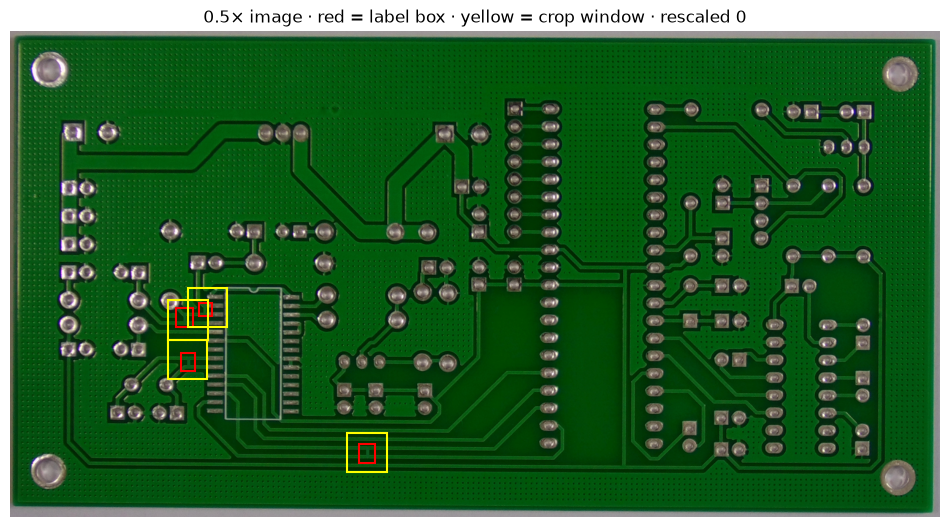

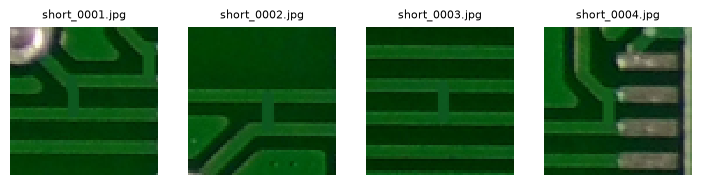

In [6]:
def defect_patches(img_s, boxes_s, rng):
    """img_s / boxes_s 已缩放。返回 [(patch, 类别 id, (left, top, 窗口边长))] 和被二次缩放的框"""
    W, H = img_s.size
    out, rescaled = [], []
    for c, x0, y0, x1, y1 in boxes_s:
        bw, bh = x1 - x0, y1 - y0
        long_side = max(bw, bh)
        # 放得下就用 64 窗口；放不下就放大窗口，让框占窗口的 RESCALE_FIT，之后再缩回 64
        S = PATCH if long_side <= PATCH else min(math.ceil(long_side / RESCALE_FIT), W, H)
        if S != PATCH:
            rescaled.append((c, x0, y0, x1, y1))
        off = MAX_OFFSET * S / PATCH                        # 偏移按窗口大小同比放大
        ox_max = max(0.0, min(off, (S - bw) / 2))           # 偏移上限：保证整个框仍在窗口内
        oy_max = max(0.0, min(off, (S - bh) / 2))
        cx = (x0 + x1) / 2 + rng.uniform(-ox_max, ox_max)
        cy = (y0 + y1) / 2 + rng.uniform(-oy_max, oy_max)
        left = int(round(min(max(cx - S / 2, 0), W - S)))
        top = int(round(min(max(cy - S / 2, 0), H - S)))
        patch = img_s.crop((left, top, left + S, top + S))
        if S != PATCH:
            patch = patch.resize((PATCH, PATCH), Image.LANCZOS)
        out.append((patch, c, (left, top, S)))
    return out, rescaled


def scaled(stem):
    img, boxes = load(stem)
    img_s = img.resize((round(img.width * SCALE), round(img.height * SCALE)), Image.BICUBIC)
    return img_s, [(c, x0 * SCALE, y0 * SCALE, x1 * SCALE, y1 * SCALE) for c, x0, y0, x1, y1 in boxes]


rng = random.Random(SEED)
img_s, boxes_s = scaled(EXAMPLE)
patches, rescaled = defect_patches(img_s, boxes_s, rng)

fig, ax = plt.subplots(figsize=(12, 6.5))
ax.imshow(img_s); draw_boxes(ax, boxes_s, color="red", label=False)
for _, c, (l, t, S) in patches:
    ax.add_patch(mpatches.Rectangle((l, t), S, S, fill=False, ec="yellow", lw=1.5))
ax.set_axis_off()
ax.set_title(f"{SCALE}× image · red = label box · yellow = crop window · rescaled {len(rescaled)}")
plt.show()

fig, axes = plt.subplots(1, len(patches), figsize=(2.2 * len(patches), 2.6), squeeze=False)
for k, (ax, (p, c, _)) in enumerate(zip(axes[0], patches)):
    ax.imshow(p, interpolation="nearest"); ax.set_axis_off()
    ax.set_title(f"{NAME[c]}_{k+1:04d}.jpg", fontsize=8)
plt.show()

### The oversized boxes

How many training boxes need the extra shrink, what scale they end up at, and what those patches look like. Left of each pair: the enlarged window at 0.5×; right: the 64×64 patch that is saved.

115 of 2185 boxes (5.3%) are rescaled; effective scale 0.17–0.37× (median 0.33×) instead of 0.5×


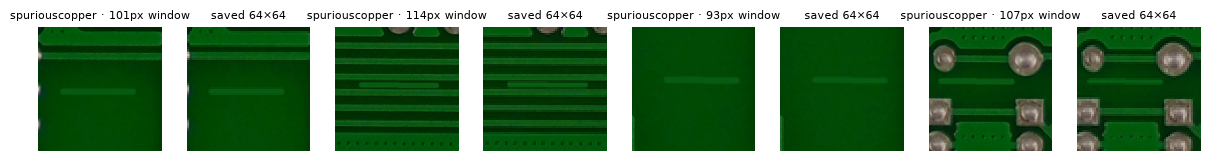

In [7]:
v = sizes * SCALE                                         # 步骤 3 中训练框的长边（0.5× 后）
big = v > PATCH
eff = SCALE * PATCH / np.ceil(v[big] / RESCALE_FIT)       # 这些块相对原图的实际缩放
print(f"{big.sum()} of {len(v)} boxes ({big.mean():.1%}) are rescaled; "
      f"effective scale {eff.min():.2f}–{eff.max():.2f}× (median {np.median(eff):.2f}×) instead of {SCALE}×")

# 找几张含超大框的训练照片
examples = []
for s in TRAIN:
    with Image.open(PKU / "images" / f"{s}.jpg") as im:
        W0, H0 = im.size
    for line in (PKU / "labels" / f"{s}.txt").read_text().splitlines():
        _, _, _, w, h = map(float, line.split())
        if max(w * W0, h * H0) * SCALE > PATCH:
            examples.append(s); break
    if len(examples) == 4:
        break

rng = random.Random(SEED)
fig, axes = plt.subplots(1, 8, figsize=(15, 2.4))
for k, s in enumerate(examples):
    im_s, bx_s = scaled(s)
    ps, _ = defect_patches(im_s, bx_s, rng)
    p, c, (l, t, S) = max(ps, key=lambda q: q[2][2])     # 这张照片里窗口最大的那个
    axes[2 * k].imshow(im_s.crop((l, t, l + S, t + S))); axes[2 * k].set_title(f"{NAME[c]} · {S}px window", fontsize=8)
    axes[2 * k + 1].imshow(p, interpolation="nearest"); axes[2 * k + 1].set_title("saved 64×64", fontsize=8)
for ax in axes:
    ax.set_axis_off()
plt.show()

### Patches from all six classes

One training photo per class, same procedure.

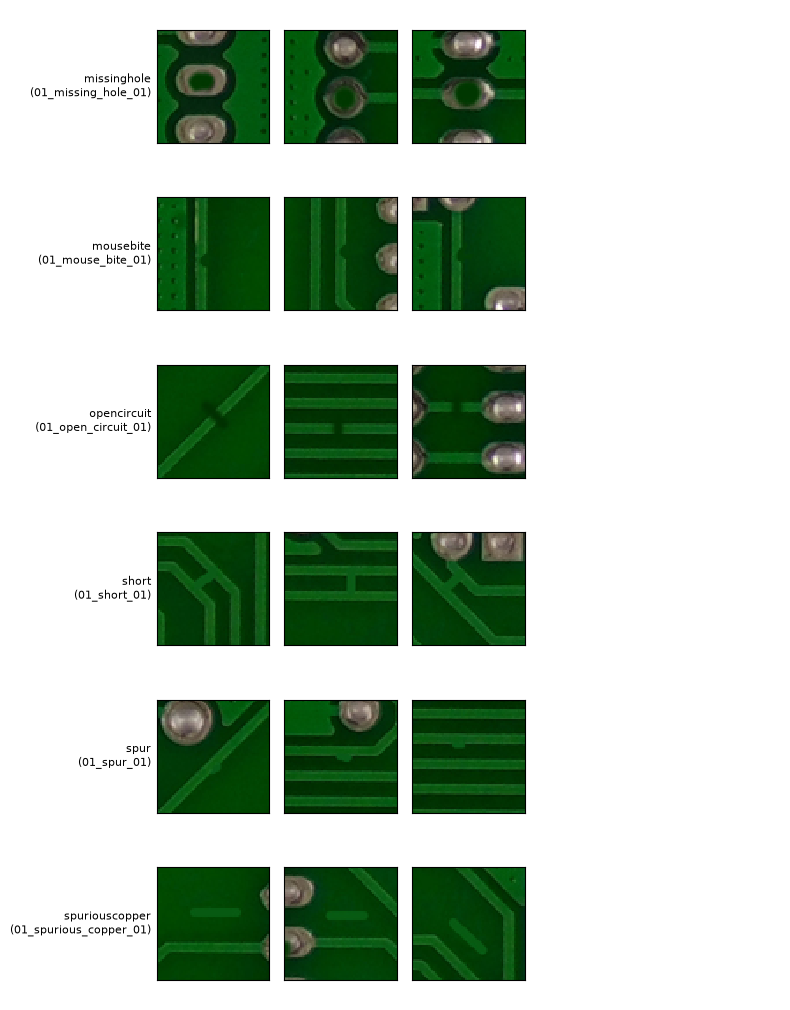

In [8]:
rng = random.Random(SEED)
rows, labels = [], []
for c, cls in enumerate(PKU_CLASSES):
    stem = next(s for s in TRAIN if s[3:].startswith(cls + "_"))   # 该类别的第一张训练照片
    ps, _ = defect_patches(*scaled(stem), rng)
    rows.append([p for p, _, _ in ps][:5]); labels.append(f"{NAME[c]}\n({stem})")

fig, axes = plt.subplots(len(rows), 5, figsize=(8, 1.7 * len(rows)), squeeze=False)
for r, row in enumerate(rows):
    for k in range(5):
        ax = axes[r, k]; ax.set_xticks([]); ax.set_yticks([])
        if k < len(row):
            ax.imshow(row[k], interpolation="nearest")
        else:
            ax.axis("off")
    axes[r, 0].set_ylabel(labels[r], rotation=0, ha="right", va="center", fontsize=8)
plt.tight_layout(); plt.show()

## Step 5 · 256×256 defect-free crops

**Problem with avoiding defects.** If windows that touch a label box are rejected, the board areas where defects often appear get fewer crops, and the crops cluster in a few empty regions. The 256 model then sees some parts of the boards much more often than others.

**Fix: remove the defects instead of avoiding them.** All photos of one board are pixel-aligned (shift ≤ 0.5 px) and every defect appears in only one photo. So the **per-pixel median over all photos of a board** is a clean template with no defects. For each photo, the pixels inside its label boxes (plus `FREE_MARGIN`) are replaced by the template. Outside the boxes the photo is kept, so its real noise and JPEG texture stay.

Crops are then placed on a **jittered grid** over each board: the valid area is split into equal cells, each cell gets one crop at a random point inside it, and the cells are shared out between the photos of that board. Every part of the board is covered about equally, and no window has to be rejected.

board 01: 120 photos; most-covered pixel lies in 13 boxes (11% of photos), so the median keeps the clean value


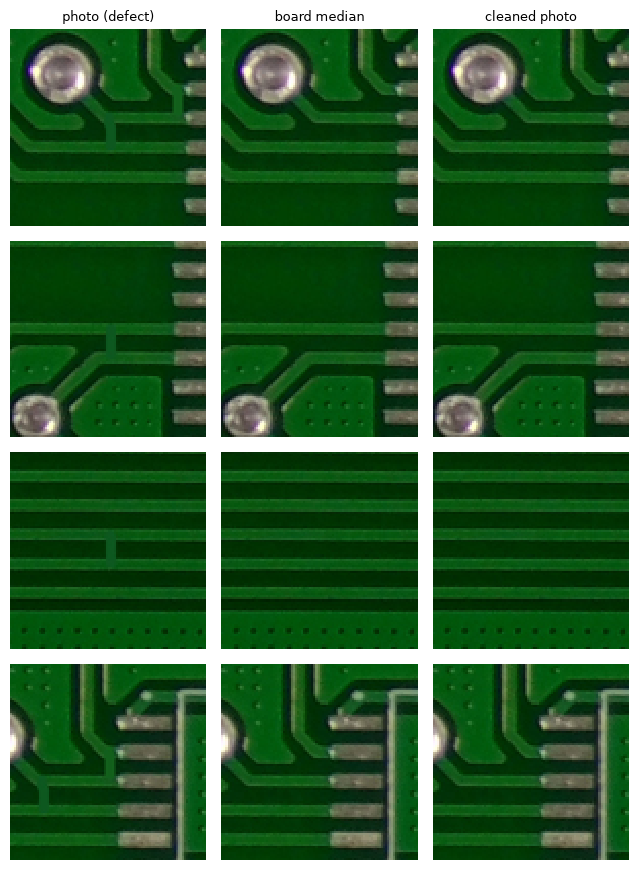

In [9]:
TPL_DIR = OUT_DIR / "templates"


def board_template(b):
    """0.5× 下该板所有照片的逐像素中值图；缓存到 data/pcb_processed/templates/"""
    path = TPL_DIR / f"board_{b}.png"
    if path.exists():
        return Image.open(path).convert("RGB")
    stems = [s for s in TRAIN + VAL if board(s) == b]
    stack = np.stack([np.asarray(scaled(s)[0]) for s in stems])        # (N, H, W, 3) uint8
    tpl = np.empty(stack.shape[1:], np.uint8)
    for r in range(0, stack.shape[1], 64):                             # 分块求中值，控制内存
        tpl[r:r + 64] = np.median(stack[:, r:r + 64], axis=0)
    TPL_DIR.mkdir(parents=True, exist_ok=True)
    Image.fromarray(tpl).save(path)
    return Image.fromarray(tpl)


def clean_photo(stem):
    """用模板覆盖标注框（外扩 FREE_MARGIN）内的像素，得到去掉缺陷的照片"""
    img_s, boxes_s = scaled(stem)
    a = np.asarray(img_s).copy()
    t = np.asarray(board_template(board(stem)))
    H, W = a.shape[:2]
    for _, x0, y0, x1, y1 in boxes_s:
        l, tp = max(0, int(x0 - FREE_MARGIN)), max(0, int(y0 - FREE_MARGIN))
        r, b = min(W, int(x1 + FREE_MARGIN) + 1), min(H, int(y1 + FREE_MARGIN) + 1)
        a[tp:b, l:r] = t[tp:b, l:r]
    return Image.fromarray(a), boxes_s


# 检查中值能否去掉缺陷：每个像素被多少比例的照片的框覆盖（需 < 50%）
b0 = board(EXAMPLE)
stems0 = [s for s in TRAIN if board(s) == b0]
Ws, Hs = img_s.size
cover = np.zeros((Hs, Ws), np.int32)
for s in stems0:
    for _, x0, y0, x1, y1 in scaled(s)[1]:
        cover[int(y0):int(y1) + 1, int(x0):int(x1) + 1] += 1
print(f"board {b0}: {len(stems0)} photos; most-covered pixel lies in {cover.max()} boxes "
      f"({cover.max() / len(stems0):.0%} of photos), so the median keeps the clean value")

clean, _ = clean_photo(EXAMPLE)
tpl = board_template(b0)
fig, axes = plt.subplots(len(boxes_s), 3, figsize=(6.5, 2.2 * len(boxes_s)), squeeze=False)
for r, (c, x0, y0, x1, y1) in enumerate(boxes_s):
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    win = (int(cx) - 48, int(cy) - 48, int(cx) + 48, int(cy) + 48)
    for ax, im_, t_ in zip(axes[r], [img_s, tpl, clean], ["photo (defect)", "board median", "cleaned photo"]):
        ax.imshow(im_.crop(win), interpolation="nearest"); ax.set_axis_off()
        if r == 0:
            ax.set_title(t_, fontsize=9)
plt.tight_layout(); plt.show()

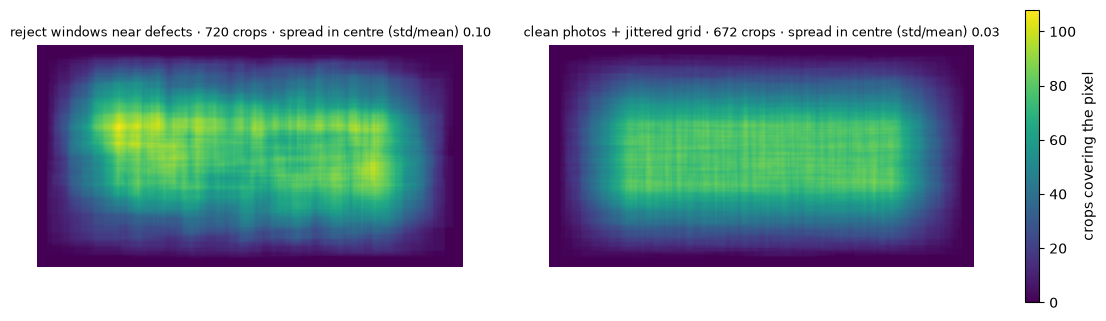

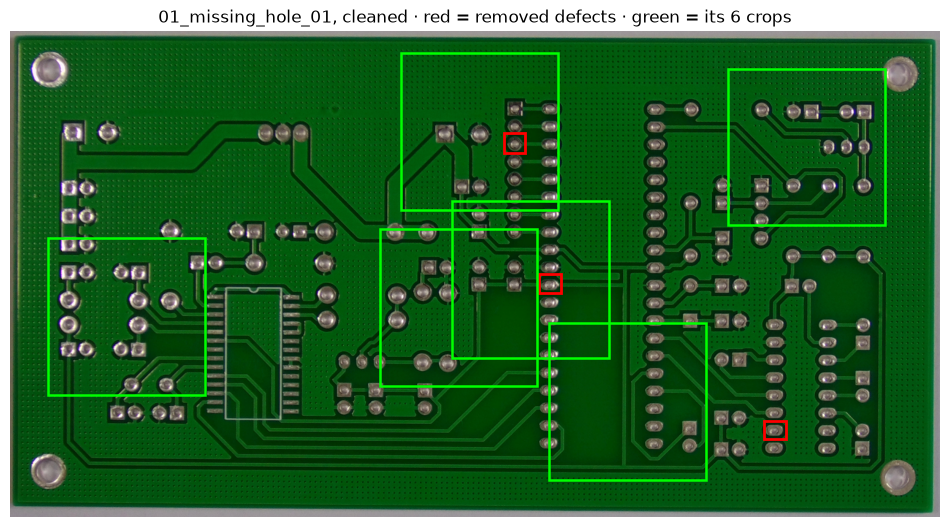

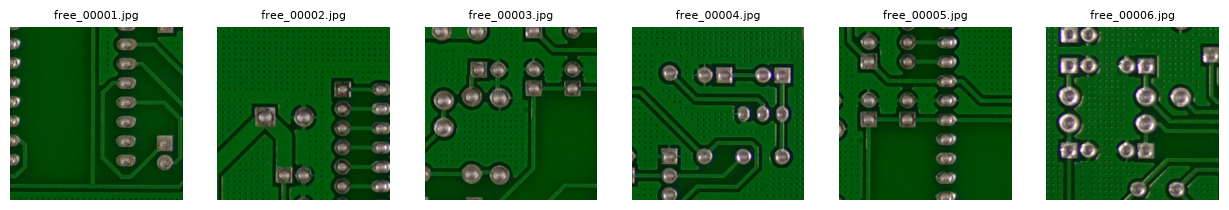

In [10]:
def grid_positions(W, H, n, rng):
    """在有效区域内放约 n 个抖动网格位置（每格一个），返回左上角坐标"""
    x_lo, x_hi = EDGE_MARGIN, W - FREE - EDGE_MARGIN
    y_lo, y_hi = EDGE_MARGIN, H - FREE - EDGE_MARGIN
    aspect = (x_hi - x_lo + 1) / (y_hi - y_lo + 1)
    ny = max(1, round(math.sqrt(n / aspect)))
    nx = max(1, round(n / ny))
    pos = [(int(x_lo + (i + rng.random()) * (x_hi - x_lo) / nx),
            int(y_lo + (j + rng.random()) * (y_hi - y_lo) / ny))
           for i in range(nx) for j in range(ny)]
    rng.shuffle(pos)
    return pos


def board_plan(n_total, rng):
    """按照片数把 n_total 个裁剪分给各训练板，再轮流分给该板的照片：{stem: [(l, t), ...]}"""
    plan = {}
    for b in sorted({board(s) for s in TRAIN}):
        stems = [s for s in TRAIN if board(s) == b]
        with Image.open(PKU / "images" / f"{stems[0]}.jpg") as im:
            W, H = round(im.width * SCALE), round(im.height * SCALE)
        pos = grid_positions(W, H, round(n_total * len(stems) / len(TRAIN)), rng)
        for k, s in enumerate(stems):
            plan[s] = pos[k::len(stems)]
    return plan


def rejection_plan(stems, per_image, rng):
    """旧方法（仅用于对比）：随机放窗口，碰到标注框就丢弃"""
    plan = {}
    for s in stems:
        _, bx = scaled(s)
        with Image.open(PKU / "images" / f"{s}.jpg") as im:
            W, H = round(im.width * SCALE), round(im.height * SCALE)
        acc = []
        for _ in range(200):
            if len(acc) == per_image:
                break
            l = rng.randint(EDGE_MARGIN, W - FREE - EDGE_MARGIN)
            t = rng.randint(EDGE_MARGIN, H - FREE - EDGE_MARGIN)
            if not any(x0 - FREE_MARGIN < l + FREE and x1 + FREE_MARGIN > l and
                       y0 - FREE_MARGIN < t + FREE and y1 + FREE_MARGIN > t for _, x0, y0, x1, y1 in bx):
                acc.append((l, t))
        plan[s] = acc
    return plan


def coverage(plan, stems, W, H):
    cov = np.zeros((H, W), np.int32)
    for s in stems:
        for l, t in plan.get(s, []):
            cov[t:t + FREE, l:l + FREE] += 1
    return cov


N_FREE_TOTAL = 3000
per_image = math.ceil(N_FREE_TOTAL / len(TRAIN))
old = rejection_plan(stems0, per_image, random.Random(SEED))
new = board_plan(N_FREE_TOTAL, random.Random(SEED))
cov_old, cov_new = coverage(old, stems0, Ws, Hs), coverage(new, stems0, Ws, Hs)
inner = np.zeros_like(cov_old, bool)
# 只在中部平台区统计：离有效区域边界不足 FREE 的像素天然被更少窗口覆盖
inner[EDGE_MARGIN + FREE:Hs - EDGE_MARGIN - FREE, EDGE_MARGIN + FREE:Ws - EDGE_MARGIN - FREE] = True

vmax = max(cov_old.max(), cov_new.max())
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, cov, name, n in zip(axes, [cov_old, cov_new], ["reject windows near defects", "clean photos + jittered grid"],
                            [sum(map(len, old.values())), sum(len(new[s]) for s in stems0)]):
    im_ = ax.imshow(cov, cmap="viridis", vmin=0, vmax=vmax)
    cv = cov[inner].std() / cov[inner].mean()
    ax.set_title(f"{name} · {n} crops · spread in centre (std/mean) {cv:.2f}", fontsize=9); ax.set_axis_off()
fig.colorbar(im_, ax=axes, fraction=0.02, label="crops covering the pixel")
plt.show()

stem = stems0[0]
clean, bx = clean_photo(stem)
fig, ax = plt.subplots(figsize=(12, 6.5))
ax.imshow(clean); draw_boxes(ax, bx, color="red", label=False, lw=2)
for l, t in new[stem]:
    ax.add_patch(mpatches.Rectangle((l, t), FREE, FREE, fill=False, ec="lime", lw=1.8))
ax.set_axis_off(); ax.set_title(f"{stem}, cleaned · red = removed defects · green = its {len(new[stem])} crops")
plt.show()

fig, axes = plt.subplots(1, len(new[stem]), figsize=(2.6 * len(new[stem]), 2.8), squeeze=False)
for k, (ax, (l, t)) in enumerate(zip(axes[0], new[stem])):
    ax.imshow(clean.crop((l, t, l + FREE, t + FREE))); ax.set_axis_off(); ax.set_title(f"free_{k+1:05d}.jpg", fontsize=8)
plt.show()
acc = [(l, t, l + FREE, t + FREE) for l, t in new[stem]]
img_s = clean

## Step 6 · Check the format with the repo's loader

Save the demo patches and crops, then read them back with `guided_diffusion.image_datasets.load_data`, the same function training will use. It should return tensors of the right size in [−1, 1], and class labels that match the file names.

defect_64 : batch (8, 3, 64, 64)  range [-1.00, 1.00]  labels [2, 0, 3, 1, 5, 1, 0, 2]


free_256  : batch (4, 3, 256, 256)  range [-1.00, 1.00]  labels [0, 0, 0, 0] (unconditional)


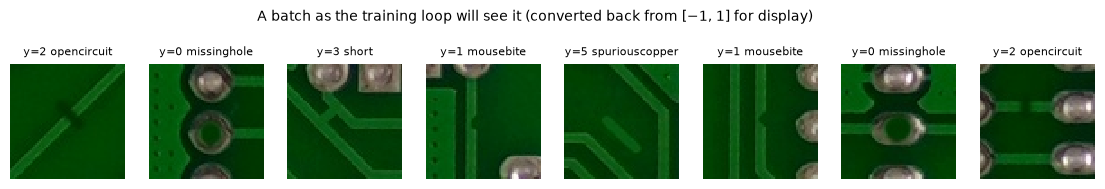

In [11]:
from guided_diffusion.image_datasets import load_data

if DEMO_DIR.exists():
    shutil.rmtree(DEMO_DIR)
(DEMO_DIR / "defect_64").mkdir(parents=True)
(DEMO_DIR / "free_256").mkdir(parents=True)

# 演示数据：每类几张缺陷块 + 上一步的无缺陷裁剪
rng = random.Random(SEED)
n = 0
for c, cls in enumerate(PKU_CLASSES):
    stem_c = next(s for s in TRAIN if s[3:].startswith(cls + "_"))
    for p, cid, _ in defect_patches(*scaled(stem_c), rng)[0]:
        n += 1
        p.save(DEMO_DIR / "defect_64" / f"{NAME[cid]}_{n:04d}.jpg", quality=95)
for k, (l, t, r, b) in enumerate(acc):
    img_s.crop((l, t, r, b)).save(DEMO_DIR / "free_256" / f"free_{k+1:05d}.jpg", quality=95)

x, y = next(load_data(data_dir=DEMO_DIR / "defect_64", batch_size=8, image_size=PATCH,
                      class_dict=PCB_JSON, shuffle=True))
print(f"defect_64 : batch {tuple(x.shape)}  range [{x.min():.2f}, {x.max():.2f}]  labels {y.tolist()}")
xf, yf = next(load_data(data_dir=DEMO_DIR / "free_256", batch_size=4, image_size=FREE, shuffle=True))
print(f"free_256  : batch {tuple(xf.shape)}  range [{xf.min():.2f}, {xf.max():.2f}]  labels {yf.tolist()} (unconditional)")

inv = {v: k for k, v in PCB_JSON.items()}
fig, axes = plt.subplots(1, 8, figsize=(14, 2.3))
for ax, im_, lab in zip(axes, x, y):
    ax.imshow(((im_.permute(1, 2, 0) + 1) / 2).clamp(0, 1).numpy(), interpolation="nearest")
    ax.set_title(f"y={lab.item()} {inv[lab.item()]}", fontsize=8); ax.set_axis_off()
fig.suptitle("A batch as the training loop will see it (converted back from [−1, 1] for display)", fontsize=10)
plt.show()

## Step 7 · Build the full training sets (optional)

Runs steps 3–5 over all 541 training photos and writes:

```
data/pcb_processed/
├── defect_64/            missinghole_0001.jpg …   one per box, oversized ones rescaled
├── defect_manifest.csv   source photo, window and effective scale of every patch
├── free_256/             free_00001.jpg …         about 3,000 crops from cleaned photos
├── free_manifest.csv     source photo and position of every crop
└── templates/            board_XX.png             per-board median (defect-free) images
```

Set `BUILD = True` to run it. The first run also builds the board templates, which takes a few minutes. Generation inputs and the real test set (boards 10–12) are a separate step.

In [12]:
BUILD = False

if BUILD:
    import csv
    for sub in ["defect_64", "free_256"]:
        d = OUT_DIR / sub
        if d.exists():
            shutil.rmtree(d)
        d.mkdir(parents=True)
    rng = random.Random(SEED)
    plan = board_plan(N_FREE_TOTAL, random.Random(SEED))
    counter = {c: 0 for c in NAME}
    n_free = n_rescaled = 0
    with open(OUT_DIR / "defect_manifest.csv", "w", newline="") as fd, \
         open(OUT_DIR / "free_manifest.csv", "w", newline="") as ff:
        wd, wf = csv.writer(fd), csv.writer(ff)
        wd.writerow(["file", "class", "source", "left", "top", "window", "effective_scale"])
        wf.writerow(["file", "source", "left", "top"])
        for i, stem in enumerate(TRAIN):
            im_s, bx_s = scaled(stem)
            ps, rs = defect_patches(im_s, bx_s, rng)
            n_rescaled += len(rs)
            for p, c, (l, t, S) in ps:
                counter[c] += 1
                name = f"{NAME[c]}_{counter[c]:04d}.jpg"
                p.save(OUT_DIR / "defect_64" / name, quality=95)
                wd.writerow([name, NAME[c], stem, l, t, S, round(SCALE * PATCH / S, 4)])
            clean, _ = clean_photo(stem)
            for l, t in plan[stem]:
                n_free += 1
                name = f"free_{n_free:05d}.jpg"
                clean.crop((l, t, l + FREE, t + FREE)).save(OUT_DIR / "free_256" / name, quality=95)
                wf.writerow([name, stem, l, t])
            if (i + 1) % 100 == 0:
                print(f"{i+1}/{len(TRAIN)} photos")
    print("defect patches per class:", {NAME[c]: n for c, n in counter.items()})
    print("of which rescaled (box larger than 64 px at 0.5×):", n_rescaled)
    print("defect-free crops:", n_free)
else:
    print("BUILD = False: nothing written. Set it to True to build data/pcb_processed/.")

BUILD = False: nothing written. Set it to True to build data/pcb_processed/.


## Step 8 · Verify and repair the defect-free crops

Erasing works by position, so it relies on two things that are not true for every photo:

- **alignment**: a few photos are shifted against their board (up to 24 px), so the template pixels pasted into their boxes do not line up and leave seams;
- **complete labels**: some photos contain defects that their label file does not mark, and those are not erased.

Outside their defects, all photos of a board are pixel-identical copies of one image. So a clean crop must equal the template crop at the same position, after the same JPEG compression (quality 95). This step compares them pixel by pixel: no pixel may differ by more than `DIFF_THRESHOLD` (0–255, largest of the three channels). Clean crops differ by 0; even a thin unlabelled spur a few pixels wide differs by 25 or more. Photos shifted by `ALIGN_TOL` px or more are not used at all.

A failing crop is replaced by **the same position cut from another aligned photo of the same board** (cleaned, and passing the same check), so the coverage of the boards, the file names and all other crops stay unchanged. Running the step again changes nothing. Results go to `free_check.csv` and `photo_shift.csv`.

photos excluded for misalignment: {'01_mouse_bite_11': 0.5, '04_spurious_copper_11': 14.0, '06_spur_08': 23.5, '06_spurious_copper_04': 3.0}


3000 crops checked · kept 2992 · replaced 8 · failed 0
after repair: median score 0.0, max 10.0 (threshold 10)


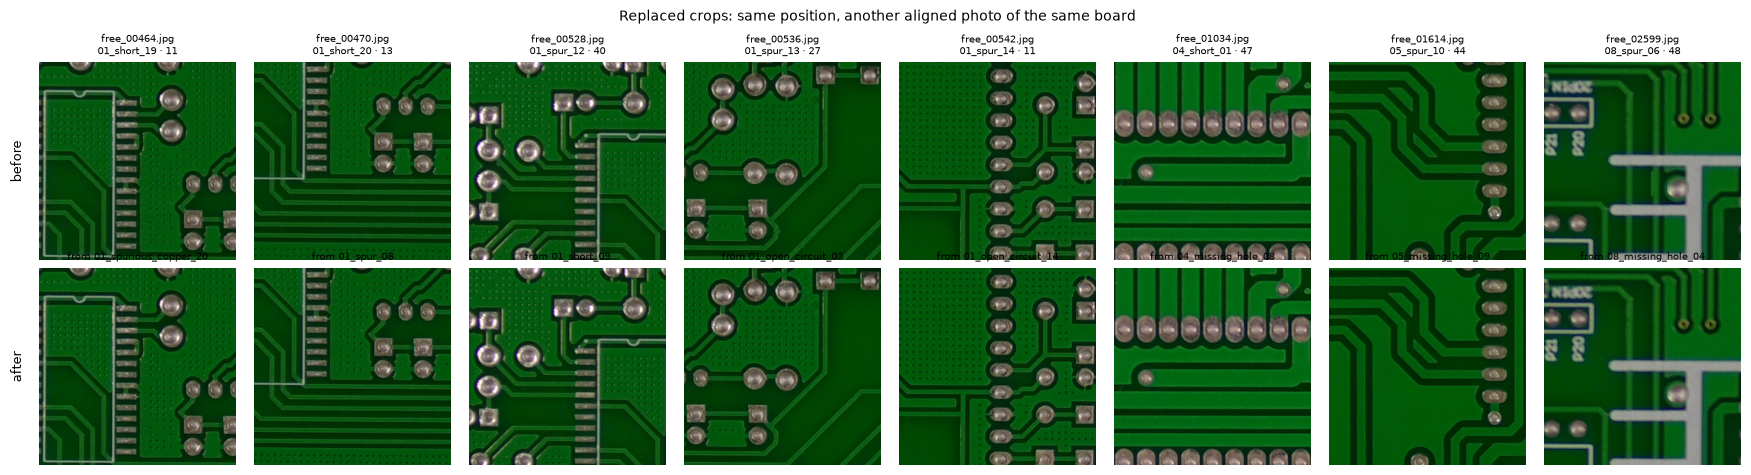

In [13]:
import csv
import functools
import io
from collections import Counter

import cv2
from skimage.registration import phase_cross_correlation

ALIGN_TOL = 0.5        # 与板模板的位移 ≥ 此值（像素，0.5× 下）的照片不用于背景裁剪
DIFF_THRESHOLD = 10    # 与“同样 JPEG 压缩后的模板裁剪”相比，任一像素允许的最大差异（0–255）


def jpeg(im):
    """按保存时的设置做一次 JPEG 压缩，使模板与裁剪可以逐像素比较"""
    buf = io.BytesIO(); im.save(buf, "JPEG", quality=95)
    return Image.open(io.BytesIO(buf.getvalue())).convert("RGB")


def local_diff(crop, ref):
    """逐像素最大差异（不做平滑）：未标注的细小缺陷、擦除接缝都会在这里出现"""
    return float(np.abs(np.asarray(crop, np.int16) - np.asarray(jpeg(ref), np.int16)).max())


@functools.lru_cache(maxsize=16)
def cleaned(stem):
    return clean_photo(stem)[0]


manifest = OUT_DIR / "free_manifest.csv"
if not manifest.exists():
    print("free_manifest.csv not found: run step 7 with BUILD = True first.")
else:
    shift_file = OUT_DIR / "photo_shift.csv"
    if shift_file.exists():
        shifts = {r["photo"]: float(r["shift_px"]) for r in csv.DictReader(open(shift_file))}
    else:                                                   # 每张训练照片相对板模板的位移，算一次后缓存
        shifts = {}
        for s in TRAIN:
            t = np.asarray(board_template(board(s)).convert("L"), np.float32)
            g = np.asarray(scaled(s)[0].convert("L"), np.float32)
            shifts[s] = float(np.abs(phase_cross_correlation(t, g, upsample_factor=10)[0]).max())
        with open(shift_file, "w", newline="") as f:
            w = csv.writer(f); w.writerow(["photo", "shift_px"]); w.writerows(sorted(shifts.items()))
    bad = {s: v for s, v in shifts.items() if v >= ALIGN_TOL}
    print("photos excluded for misalignment:", bad)

    rows = list(csv.DictReader(open(manifest)))
    rng = random.Random(SEED + 1)
    report, changed = [], []
    for r in rows:
        stem, l, t = r["source"], int(r["left"]), int(r["top"])
        ref = board_template(board(stem)).crop((l, t, l + FREE, t + FREE))
        crop = Image.open(OUT_DIR / "free_256" / r["file"]).convert("RGB")
        score = local_diff(crop, ref)
        if stem not in bad and score <= DIFF_THRESHOLD:
            report.append([r["file"], stem, round(score, 1), "kept", "", ""])
            continue
        candidates = [s for s in TRAIN if board(s) == board(stem) and s != stem and s not in bad]
        rng.shuffle(candidates)
        for s in candidates:
            new = cleaned(s).crop((l, t, l + FREE, t + FREE))
            new_score = local_diff(jpeg(new), ref)
            if new_score <= DIFF_THRESHOLD:
                changed.append((r["file"], crop, new, stem, s, score))
                new.save(OUT_DIR / "free_256" / r["file"], quality=95)
                report.append([r["file"], stem, round(score, 1), "replaced", s, round(new_score, 1)])
                r["source"] = s
                break
        else:
            report.append([r["file"], stem, round(score, 1), "failed", "", ""])
    with open(manifest, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
    with open(OUT_DIR / "free_check.csv", "w", newline="") as f:
        w = csv.writer(f); w.writerow(["file", "old_source", "old_score", "status", "new_source", "new_score"]); w.writerows(report)
    st = Counter(x[3] for x in report)
    print(f"{len(rows)} crops checked · kept {st['kept']} · replaced {st['replaced']} · failed {st['failed']}")
    scores = np.array([x[2] if x[3] == "kept" else x[5] for x in report if x[3] != "failed"], float)
    print(f"after repair: median score {np.median(scores):.1f}, max {scores.max():.1f} (threshold {DIFF_THRESHOLD})")

    if changed:
        n = min(8, len(changed))
        fig, axes = plt.subplots(2, n, figsize=(2.2 * n, 4.8), squeeze=False)
        for k, (f, old, new, s_old, s_new, sc) in enumerate(changed[:n]):
            axes[0, k].imshow(old); axes[0, k].set_title(f"{f}\n{s_old} · {sc:.0f}", fontsize=7)
            axes[1, k].imshow(new); axes[1, k].set_title(f"from {s_new}", fontsize=7)
            axes[0, k].axis("off"); axes[1, k].axis("off")
        axes[0, 0].text(-20, 128, "before", rotation=90, va="center", ha="right", fontsize=9)
        axes[1, 0].text(-20, 128, "after", rotation=90, va="center", ha="right", fontsize=9)
        fig.suptitle("Replaced crops: same position, another aligned photo of the same board", fontsize=10)
        plt.tight_layout(); plt.show()